# Task 4 — Original screenshot EDA

Verify → inspect → encode raw pixels → save. The CSV labels are the source of truth: `7-11k`, `fiveN`, `freefried`, `pube`, `roblock`. The overview and datacard disagree on integer-to-game mappings, so no integer mapping is inferred. Images are 230 × 120 JPEGs. Macro F₁ is the competition metric. `image_sha256` is retained only for duplicate-aware validation, never as a model feature.

The plots below are part of the saved, executed review: class balance, example images, resolution, color and brightness, and train/test shift.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task4" / "data" / "raw"
from src.pipeline.random_seed import set_seed
SEED = set_seed()
import json
import numpy as np
import pandas as pd
from IPython.display import display

from src.task4.image_features import extract_image
from src.pipeline.save_data import save_data

# Verify

In [2]:
train_raw = pd.read_csv(RAW / "train.csv")
test_raw = pd.read_csv(RAW / "test-outdate-12-11-2026.csv")
assert train_raw.columns.tolist() == test_raw.columns.tolist() == ["id", "class"]
assert train_raw["id"].is_unique and test_raw["id"].is_unique
assert not train_raw["id"].isna().any() and not test_raw["id"].isna().any()
assert train_raw["class"].notna().all() and test_raw["class"].isna().all()
assert not (set(train_raw.id) & set(test_raw.id))
display(train_raw["class"].value_counts().to_frame("train_count"))
print("Train/test rows:", len(train_raw), len(test_raw))
print("Missing train images:", sum(not (RAW / "train" / f"{x}.jpg").is_file() for x in train_raw.id))
print("Missing test images:", sum(not (RAW / "test" / f"{x}.jpg").is_file() for x in test_raw.id))


,train_count
class,
7-11k,12429
pube,5926
freefried,5596
fiveN,4407
roblock,3188


Train/test rows: 31546 25889


Missing train images: 0


Missing test images: 0


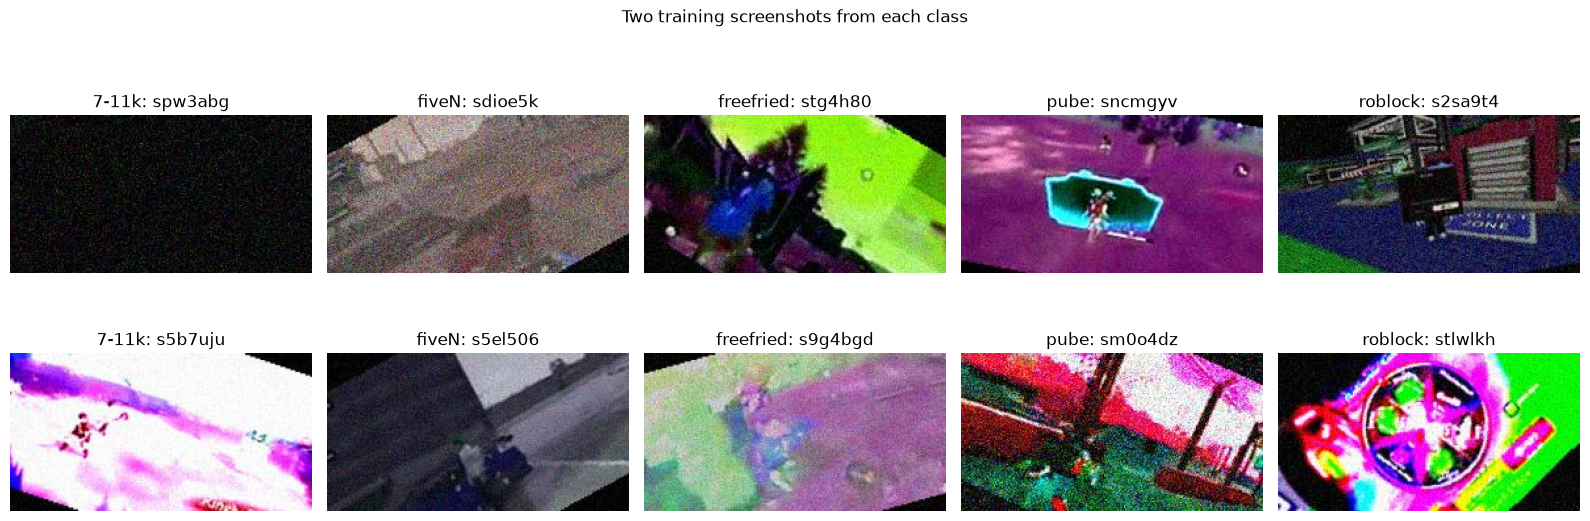

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for col, label in enumerate(sorted(train_raw["class"].unique())):
    samples = train_raw.loc[train_raw["class"].eq(label), "id"].sample(n=2, random_state=SEED)
    for row, image_id in enumerate(samples):
        with Image.open(RAW / "train" / f"{image_id}.jpg") as image:
            axes[row, col].imshow(image)
        axes[row, col].set_title(f"{label}: {image_id}")
        axes[row, col].axis("off")
plt.suptitle("Two training screenshots from each class")
plt.tight_layout()

# Clean and encode

There are no CSV predictor columns. Decode each competition image, normalize RGB to [0, 1], and resize to 16 × 8 for a compact pixel baseline. Width and height are diagnostics. No operation learns from labels or Test.

In [4]:
def make_frame(manifest, split):
    rows = []
    for index, row in enumerate(manifest.itertuples(index=False)):
        rows.append({"id": row.id, **extract_image(RAW / split / f"{row.id}.jpg")})
        if (index + 1) % 5000 == 0:
            print(split, index + 1, "images")
    frame = pd.DataFrame(rows)
    frame.insert(1, "class", manifest["class"].to_numpy())
    return frame

train_df = make_frame(train_raw, "train")
test_df = make_frame(test_raw, "test")

train 5000 images


train 10000 images


train 15000 images


train 20000 images


train 25000 images


train 30000 images


test 5000 images


test 10000 images


test 15000 images


test 20000 images


test 25000 images


## Class balance and image appearance

The five labels are taken verbatim from `train.csv`. Count and share matter for macro F₁: each class contributes equally even when the dataset has unequal class sizes. The contact sheet lets us spot overlays, UI patterns, and visual ambiguity.

,count,share_pct
class,,
7-11k,12429,39.40
fiveN,4407,13.97
freefried,5596,17.74
pube,5926,18.79
roblock,3188,10.11


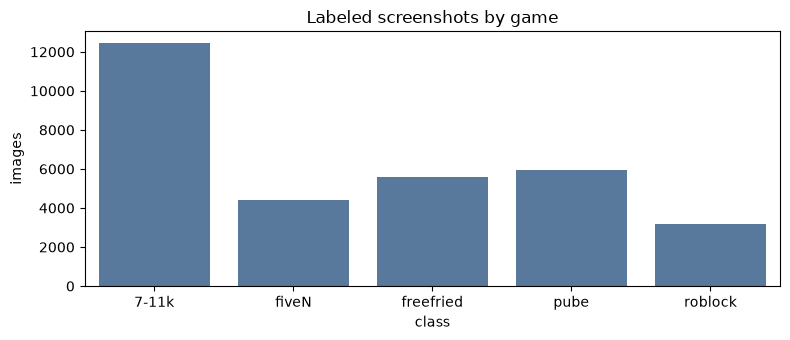

In [5]:
counts = train_raw["class"].value_counts().sort_index()
class_summary = pd.DataFrame({"count": counts, "share_pct": (counts / len(train_raw) * 100).round(2)})
display(class_summary)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=class_summary.index, y=class_summary["count"], ax=ax, color="#4c78a8")
ax.set(title="Labeled screenshots by game", xlabel="class", ylabel="images")
plt.tight_layout()

## Resolution, color, brightness, and train/test shift

The small RGB pixels are enough for a first view of broad color differences. These summaries are descriptive only; no Test statistic is used to fit a model. Dimension and duplicate checks help flag unexpected image files before modeling.

train   test
mean red         0.451  0.414
     green       0.451  0.413
     blue        0.451  0.414
     brightness  0.451  0.414
     contrast    0.191  0.196
std  red         0.220  0.225
     green       0.222  0.225
     blue        0.221  0.225
     brightness  0.202  0.191
     contrast    0.088  0.093

,,train,test
width,height,,
230,120,31546,25889


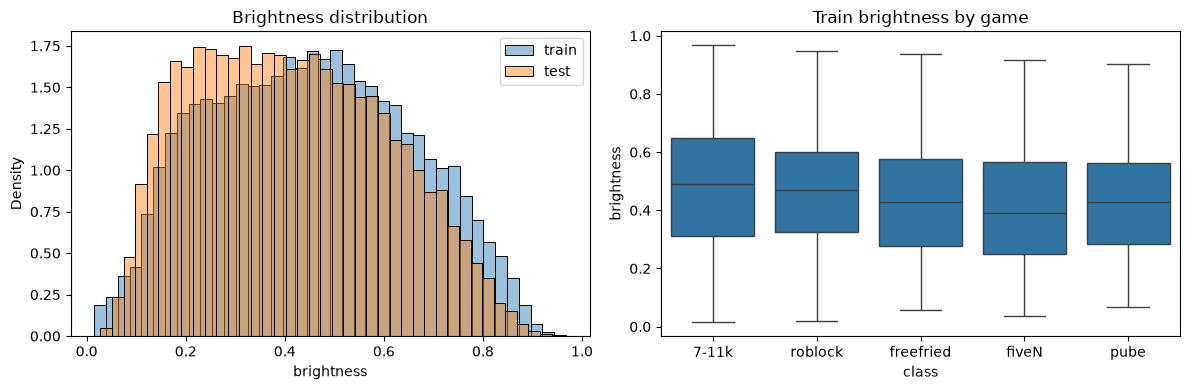

In [6]:
def summarize_pixels(frame):
    values = frame[[f"px_{i:03d}" for i in range(384)]].to_numpy(dtype=np.float32).reshape(-1, 8, 16, 3)
    channels = values.mean(axis=(1, 2))
    out = pd.DataFrame(channels, columns=["red", "green", "blue"])
    out["brightness"] = values.mean(axis=(1, 2, 3))
    out["contrast"] = values.std(axis=(1, 2, 3))
    return out

train_visual = summarize_pixels(train_df)
test_visual = summarize_pixels(test_df)
train_visual["class"] = train_df["class"].to_numpy()
quality = pd.DataFrame({
    "train": train_visual.drop(columns="class").agg(["mean", "std"]).stack(),
    "test": test_visual.agg(["mean", "std"]).stack(),
})
display(quality.round(3))
display(pd.DataFrame({"train": train_df[["width", "height"]].value_counts(),
                      "test": test_df[["width", "height"]].value_counts()}).fillna(0).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_visual["brightness"], bins=40, stat="density", alpha=.45, label="train", ax=axes[0])
sns.histplot(test_visual["brightness"], bins=40, stat="density", alpha=.45, label="test", ax=axes[0])
axes[0].legend(); axes[0].set_title("Brightness distribution")
sns.boxplot(data=train_visual, x="class", y="brightness", ax=axes[1], showfliers=False)
axes[1].set_title("Train brightness by game")
plt.tight_layout()

### EDA observation

`7-11k` is the largest class (12,429/31,546, 39.4%) and `roblock` the smallest (3,188, 10.1%). Macro F₁ will give both equal weight. The sampled screenshots show different game interfaces but also varied scenes within a class, so a model should use spatial and texture information as well as broad color. Test images are slightly darker on average; this is a descriptive distribution check, not a training adjustment.

# Explore image quality and leakage

In [7]:
display(pd.DataFrame({"train": train_df[["width", "height"]].value_counts(),
                      "test": test_df[["width", "height"]].value_counts()}).fillna(0).astype(int))
duplicate_groups = train_df.groupby("image_sha256")["class"].agg(["size", "nunique"])
print("Repeated training-image hashes:", int((duplicate_groups["size"] > 1).sum()))
print("Conflicting labels on identical images:", int((duplicate_groups["nunique"] > 1).sum()))
print("Exact train/test image overlap:", len(set(train_df.image_sha256) & set(test_df.image_sha256)))
assert (duplicate_groups["nunique"] == 1).all(), "Conflicting labels need manual review"
assert not (set(train_df.image_sha256) & set(test_df.image_sha256)), "Review exact train/test overlap"

,,train,test
width,height,,
230,120,31546,25889


Repeated training-image hashes: 0
Conflicting labels on identical images: 0
Exact train/test image overlap: 0


# Save dataset

In [8]:
assert train_df.columns.tolist() == test_df.columns.tolist()
data_info = save_data(task=4, name="eda_original_v1", train=train_df, test=test_df,
    card={"source": "task4/data/raw/train.csv, test-outdate-12-11-2026.csv, train/*.jpg, test/*.jpg",
          "features": "16x8 RGB pixels normalized to [0,1]",
          "excluded_from_models": ["id", "class", "image_sha256", "width", "height"],
          "leakage": "exact image hashes checked; duplicate groups separated in validation"})
print(json.dumps(data_info, indent=2)[:1200])

{
  "name": "eda_original_v1",
  "task": "task4",
  "created_at": "2026-11-06T05:16:17+00:00",
  "card": {
    "source": "task4/data/raw/train.csv, test-outdate-12-11-2026.csv, train/*.jpg, test/*.jpg",
    "features": "16x8 RGB pixels normalized to [0,1]",
    "excluded_from_models": [
      "id",
      "class",
      "image_sha256",
      "width",
      "height"
    ],
    "leakage": "exact image hashes checked; duplicate groups separated in validation"
  },
  "format": "parquet",
  "splits": {
    "train": {
      "path": "task4/data/eda/eda_original_v1-train.parquet",
      "card_path": "task4/data/eda/eda_original_v1-train.json",
      "rows": 31546,
      "columns": {
        "id": "str",
        "class": "str",
        "image_sha256": "str",
        "width": "int64",
        "height": "int64",
        "px_000": "float32",
        "px_001": "float32",
        "px_002": "float32",
        "px_003": "float32",
        "px_004": "float32",
        "px_005": "float32",
        "px_00